Graph with 167 nodes and 1086 edges {'dreams': 111, 'waking': 30, 'equal': 26}


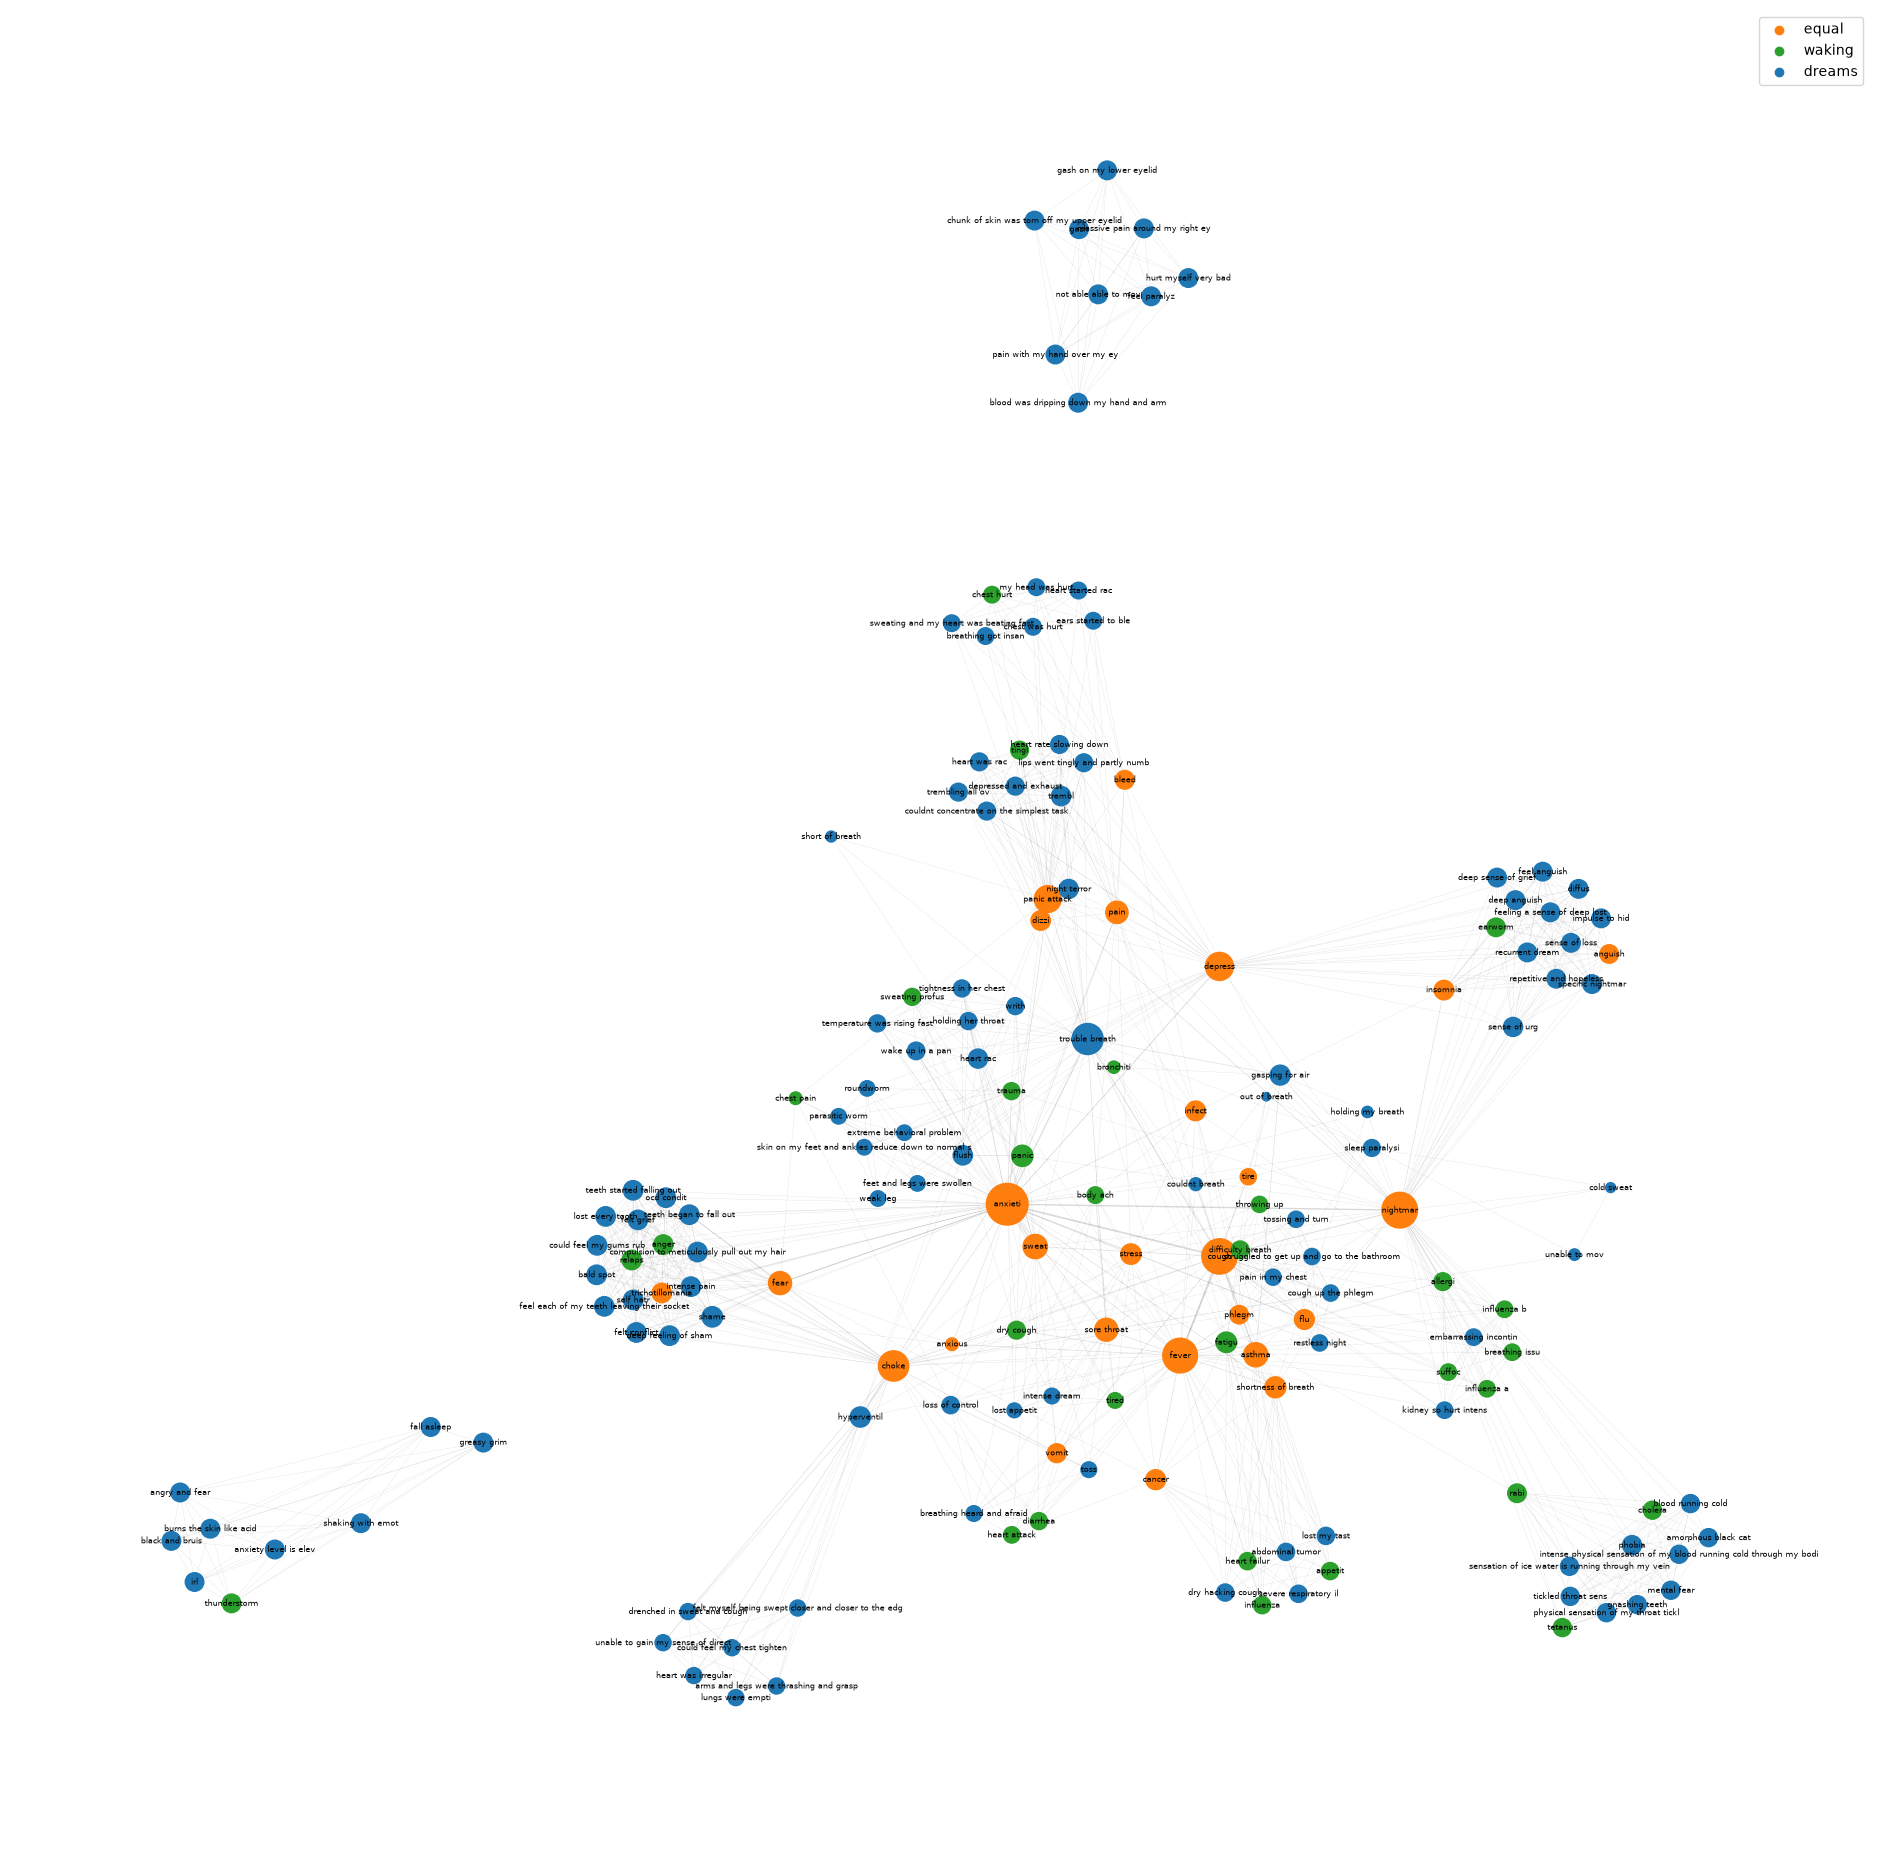

In [35]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

df = pd.read_csv("./data/co_occurrence_graph.csv")
G = nx.from_pandas_edgelist(df, "sym1", "sym2", edge_attr="count")

COVID_TERMS = ("covid", "corona", "pandem", "virus")  # stemmed: "pandemic" is "pandem"; "virus" also catches misspellings
G = G.subgraph(n for n in G if not any(t in n for t in COVID_TERMS))

# paper has 3 classes; "only in dreams" counts as typical of dream reports
classes = {"only_in_dreams_covid.csv": "dreams", "equally_prevalent.csv": "equal",
           "more_prev_in_dreams_covid.csv": "dreams", "more_prev_in_twitter_covid.csv": "waking"}
cls = {}
for f, c in classes.items():
    d = pd.read_csv(f"./data/{f}")
    cls.update(dict.fromkeys(d.filter(like="sym").iloc[:, 0], c))
nx.set_node_attributes(G, cls, "cls")

MIN_DEGREE = 8  # core: nodes with 5+ edges
core = G.subgraph(n for n, d in G.degree() if d >= MIN_DEGREE)
pr = nx.pagerank(core, weight="count")
PR_CUTOFF = pd.Series(pr).quantile(0.10)  # drop the bottom 10% by PageRank
core = core.subgraph(n for n in core if pr[n] >= PR_CUTOFF)
print(core, pd.Series(nx.get_node_attributes(core, "cls")).value_counts().to_dict())

# node diameter: PageRank min-max scaled to [MIN_SIZE, MAX_SIZE]; sqrt so hubs don't dwarf the rest
MIN_SIZE, MAX_SIZE = 6, 30
p = pd.Series(pr)[list(core)]
size = (MIN_SIZE + (MAX_SIZE - MIN_SIZE) * ((p - p.min()) / (p.max() - p.min())) ** 0.5).to_dict()

COLORS = {"equal": "tab:orange", "waking": "tab:green", "dreams": "tab:blue"}  # as in the paper's caption

pos = nx.spring_layout(core, weight="count", seed=0, k=0.3)
plt.figure(figsize=(24, 24))  # large so all labels stay legible when zoomed
nx.draw_networkx_edges(core, pos, width=[0.2 * c for _, _, c in core.edges(data="count")], alpha=0.15)
nx.draw_networkx_nodes(core, pos, node_size=[size[n] ** 2 for n in core],  # matplotlib node_size is area
                       node_color=[COLORS[core.nodes[n]["cls"]] for n in core])
nx.draw_networkx_labels(core, pos, font_size=6)
for c, col in COLORS.items():
    plt.scatter([], [], color=col, label=c)
plt.legend()
plt.axis("off")
plt.show()

In [36]:
from matplotlib.colors import to_rgb

out = core.copy()
nx.set_node_attributes(out, pr, "pagerank")
nx.set_edge_attributes(out, nx.get_edge_attributes(out, "count"), "weight")  # Gephi reads edge weight from "weight"
for n, c in out.nodes(data="cls"):
    r, g, b = (int(255 * v) for v in to_rgb(COLORS[c]))
    out.nodes[n]["viz"] = {"color": {"r": r, "g": g, "b": b, "a": 1.0}, "size": size[n]}
nx.write_gexf(out, "./figure3_core.gexf")